# Machine Learning Assignment 2
## Comparative Analysis of Classification Algorithms

### 1. Introduction

Machine Learning is a branch of Artificial Intelligence that enables computer systems to learn patterns from data and make predictions based on previous observations.

Classification is a supervised machine learning technique used to predict the category or class of an observation based on its input features.

In this assignment, five machine learning classification algorithms are implemented and evaluated using the Dry Bean Dataset.

### 1.1 Problem Statement

The objective of this project is to develop and compare five supervised machine learning classification algorithms to predict the type of dry bean using its physical characteristics.

The five algorithms implemented are:

1. Logistic Regression
2. Decision Tree Classifier
3. K-Nearest Neighbors (KNN)
4. Gaussian Naive Bayes
5. Support Vector Machine (SVM)

The models are evaluated using Accuracy, AUC, Precision, Recall, F1-score and Matthews Correlation Coefficient (MCC).

The final objective is to identify the best-performing classifier based on the experimental results.

## 2. Importing Required Libraries

Python libraries are imported to perform data manipulation, visualization, preprocessing, model development and performance evaluation.

The following libraries are used:

- Pandas and NumPy for data manipulation.
- Matplotlib and Seaborn for data visualization.
- Scikit-learn for preprocessing, classification and evaluation.
- Joblib for saving trained machine learning models.

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

project_path = "/content/drive/MyDrive/ML_Assignment_2"

print(os.listdir(project_path))

['Dataset ', 'Notebooks ', 'Models ', 'Streamlit_App ', 'Screenshots ', 'Final_Submission ']


In [3]:
!pip install pandas numpy scikit-learn matplotlib seaborn joblib streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 123.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 139.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


## 3. Dataset Description

The Dry Bean Dataset is obtained from the UCI Machine Learning Repository.

Dataset source: https://archive.ics.uci.edu/dataset/602/dry+bean+dataset

The dataset contains physical measurements of dry beans extracted from images. These measurements describe the size and shape characteristics of different bean varieties.

### Dataset characteristics

- Original number of records: 13,611
- Number of input features: 16
- Target variable: Class
- Number of classes: 7
- Data type: Numerical features and categorical target
- Missing values: None

The seven bean varieties are DERMASON, SIRA, SEKER, HOROZ, CALI, BARBUNYA and BOMBAY.

## 4. Loading the Dataset

The dataset is stored in Google Drive and loaded into a Pandas DataFrame using the `read_excel()` function.

The first five records are displayed to verify that the dataset has been loaded correctly.

In [12]:
import pandas as pd
dataset_path = "/content/drive/MyDrive/ML_Assignment_2/Dataset /Dry_Bean_Dataset.xlsx"
df = pd.read_excel(dataset_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


## 5. Initial Dataset Exploration

Initial exploration is performed to understand the dimensions, column names and data types of the dataset.

The `shape` attribute provides the number of rows and columns, while `info()` provides information about data types and non-null values.

The column names are also examined to identify the input features and target variable.

In [38]:
print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nFirst five records:")
display(df.head())

Dataset dimensions: (13543, 17)

Column names:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13543 entries, 0 to 13542
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13543 non-null  int64  
 1   Perimeter        13543 non-null  float64
 2   MajorAxisLength  13543 non-null  float64
 3   MinorAxisLength  13543 non-null  float64
 4   AspectRation     13543 non-null  float64
 5   Eccentricity     13543 non-null  float64
 6   ConvexArea       13543 non-null  int64  
 7   EquivDiameter    13543 non-null  float64
 8   Extent           13543 non-null  float64
 9   Solidity         13543 non-null  float64
 10  roundness        13

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


## 6. Data Quality Analysis

The dataset is examined for missing values and duplicate records.

Missing values can affect the training process, while duplicate records may introduce repeated observations.

The number of records belonging to each target class is also examined to understand the class distribution.

In [39]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nNumber of duplicate records:")
print(df.duplicated().sum())

print("\nNumber of target classes:")
print(df["Class"].nunique())

print("\nClass distribution:")
print(df["Class"].value_counts())

Missing values in each column:
Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

Total missing values: 0

Number of duplicate records:
0

Number of target classes:
7

Class distribution:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1860
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


## 7. Visualisation of Target Class Distribution

A count plot is used to visualise the distribution of the seven dry bean varieties.

This visualisation helps identify whether the dataset contains balanced or imbalanced classes.

Understanding class distribution is important when selecting suitable evaluation metrics and splitting the dataset.

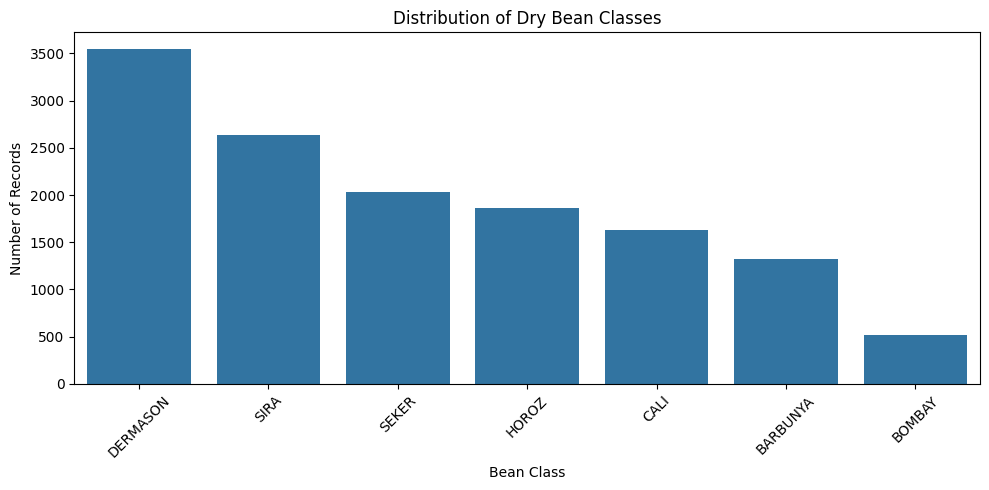

In [41]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Class",
    order=df["Class"].value_counts().index
)

plt.title("Distribution of Dry Bean Classes")
plt.xlabel("Bean Class")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### 7.1 Observations

The dataset contains seven dry bean varieties with different numbers of observations.

DERMASON has the highest number of records, while BOMBAY has the lowest.

Therefore, the target class distribution is imbalanced. Stratified train-test splitting and weighted evaluation metrics are used to account for these differences.

## 8. Data Preprocessing

Data preprocessing is performed to prepare the dataset for machine learning.

The following operations are carried out:

1. Remove exact duplicate records.
2. Separate independent variables (features) and the dependent variable (target).
3. Retain all 16 numerical features as input variables.
4. Retain the Class column as the target variable.

Feature scaling is performed later inside the machine learning pipelines to prevent information leakage from the testing data.

In [42]:
print("Rows before removing duplicates:", df.shape[0])

df = df.drop_duplicates().reset_index(drop=True)

print("Rows after removing duplicates:", df.shape[0])

print("Remaining duplicate records:", df.duplicated().sum())

# Separate features and target
X = df.drop("Class", axis=1)
y = df["Class"]

print("\nFeatures shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(y.unique())

Rows before removing duplicates: 13543
Rows after removing duplicates: 13543
Remaining duplicate records: 0

Features shape: (13543, 16)
Target shape: (13543,)

Target classes:
['SEKER' 'BARBUNYA' 'BOMBAY' 'CALI' 'HOROZ' 'SIRA' 'DERMASON']


### 8.1 Preprocessing Observations

A total of 68 duplicate records were identified and removed.

After duplicate removal, the dataset contains 13,543 records and 16 independent numerical features.

The Class column is used as the target variable for multiclass classification.

## 9. Splitting the Dataset into Training and Testing Sets

The preprocessed dataset is divided into training and testing subsets.

An 80:20 split is used, with 80% of the data allocated for training and 20% for testing.

The `stratify=y` parameter maintains the approximate proportion of each bean class in both subsets.

A fixed random state of 42 is used to ensure reproducibility.

The same training and testing subsets are used for all five classification algorithms.

In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("Training features:", X_train.shape[1])
print("Testing features:", X_test.shape[1])

Training records: 10834
Testing records: 2709
Training features: 16
Testing features: 16


### 9.1 Train-Test Split Observations

The dataset was divided into:

- Training records: 10,834
- Testing records: 2,709

The training data is used to fit the models, while the testing data is used to evaluate their performance on previously unseen observations.

## 10. Building Classification Models

Five supervised machine learning algorithms are selected for this comparative study.

**1. Logistic Regression:** A classification algorithm that estimates class probabilities using a logistic function.

**2. Decision Tree:** A tree-based algorithm that makes predictions through feature-based decision rules.

**3. K-Nearest Neighbors:** A distance-based algorithm that predicts the class based on nearby training observations.

**4. Gaussian Naive Bayes:** A probabilistic classifier based on Bayes' theorem and Gaussian feature distributions.

**5. Support Vector Machine:** A classification algorithm that identifies decision boundaries between different classes.

StandardScaler is applied to Logistic Regression, KNN, Gaussian Naive Bayes and SVM. Decision Tree does not require feature scaling.

Scikit-learn pipelines are used to combine preprocessing and classification where required.

In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

print("All five classifier libraries imported successfully!")

All five classifier libraries imported successfully!


In [18]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=2000))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Gaussian Naive Bayes": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", GaussianNB())
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(probability=True, random_state=42))
    ])
}

print("Five classifiers created successfully!")

for name in models:
    print("-", name)

Five classifiers created successfully!
- Logistic Regression
- Decision Tree
- KNN
- Gaussian Naive Bayes
- SVM


## 11. Training the Classification Models

All five classifiers are trained using the same training dataset.

The `fit()` method is used to train each model on the training features and corresponding target labels.

The trained models are stored in a dictionary so that they can be reused during model evaluation, comparison and deployment.

No testing data is used during model training.

In [19]:
trained_models = {}

for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train, y_train)

    trained_models[name] = model

print("\nAll five models trained successfully!")

Training Logistic Regression...
Training Decision Tree...
Training KNN...
Training Gaussian Naive Bayes...
Training SVM...

All five models trained successfully!


## 12. Model Evaluation

The trained models are evaluated using the independent testing dataset.

The following six metrics are calculated:

1. **Accuracy:** Proportion of correctly classified observations.
2. **AUC:** Measures the ability of the classifier to distinguish between classes.
3. **Precision:** Measures the correctness of positive class predictions.
4. **Recall:** Measures how many actual class observations are correctly identified.
5. **F1-score:** Harmonic mean of precision and recall.
6. **MCC:** Measures the correlation between actual and predicted classifications.

Since the problem involves seven classes, weighted averaging is used for Precision, Recall and F1-score. Weighted One-vs-Rest AUC is used for multiclass AUC evaluation.

All models are evaluated using the same testing records to ensure a fair comparison.

In [44]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

import pandas as pd

results = []

for name, model in trained_models.items():

    # Predictions
    y_pred = model.predict(X_test)

    # Prediction probabilities for AUC
    y_proba = model.predict_proba(X_test)

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)

    auc = roc_auc_score(
        y_test,
        y_proba,
        multi_class="ovr",
        average="weighted",
        labels=model.classes_
    )

    precision = precision_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    mcc = matthews_corrcoef(y_test, y_pred)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC": mcc
    })

results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
display(results_df.round(4))

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9192,0.9934,0.9197,0.9192,0.9193,0.9023
1,Decision Tree,0.8966,0.9363,0.8965,0.8966,0.8964,0.8750
2,KNN,0.9155,0.9811,0.9163,0.9155,0.9157,0.8978
3,Gaussian Naive Bayes,0.8970,0.9899,0.8997,0.8970,0.8972,0.8762
4,SVM,0.9210,0.9933,0.9214,0.9210,0.9211,0.9045


### Importing Confusion Matrix Evaluation Tools

The confusion matrix and its display utility are imported from Scikit-learn to visualise the classification performance of each trained model.

In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print("Confusion matrix libraries imported successfully!")

Confusion matrix libraries imported successfully!


## 13. Confusion Matrix Analysis

A confusion matrix is used to evaluate the classification predictions of each model.

It compares the actual bean classes with the predicted bean classes.

The diagonal elements represent correctly classified observations, while the off-diagonal elements represent misclassifications.

Confusion matrices are generated separately for all five classifiers to understand their class-wise prediction performance.

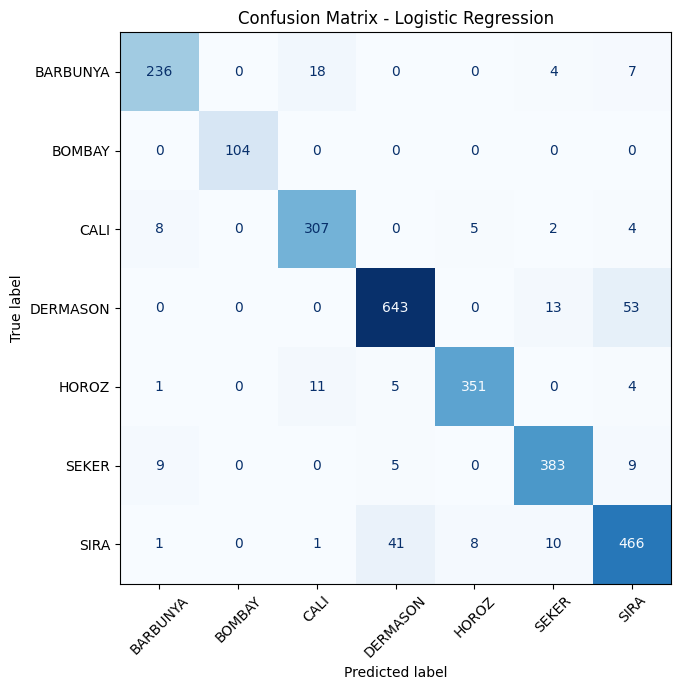

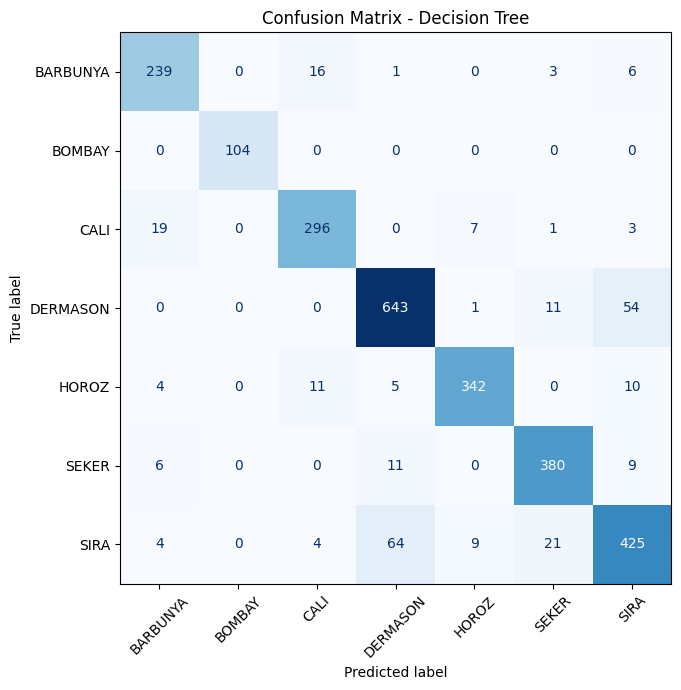

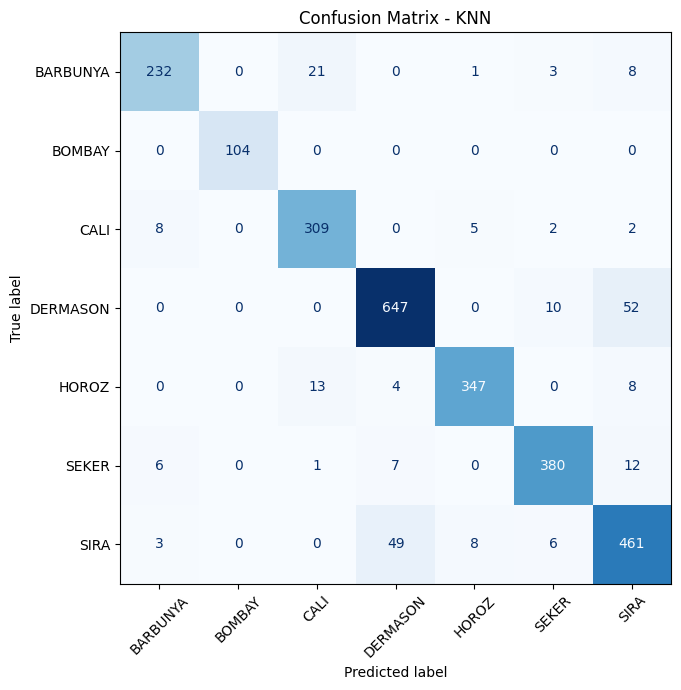

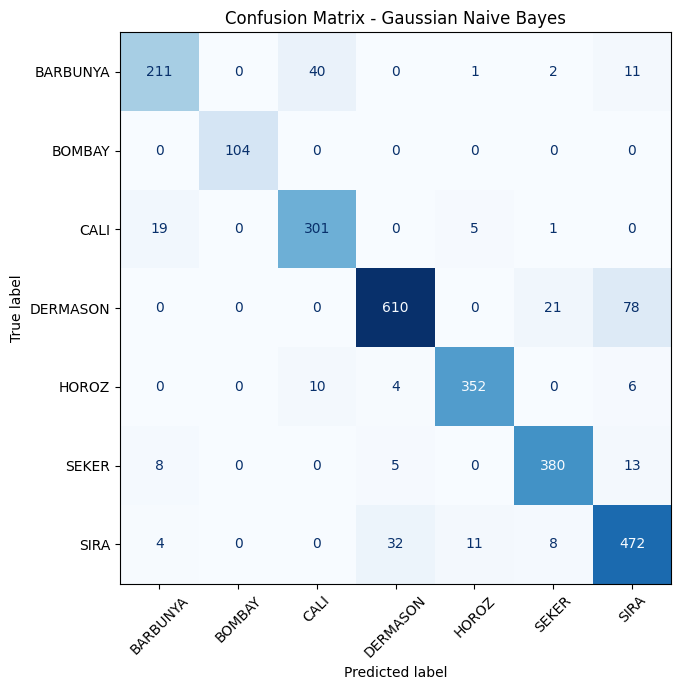

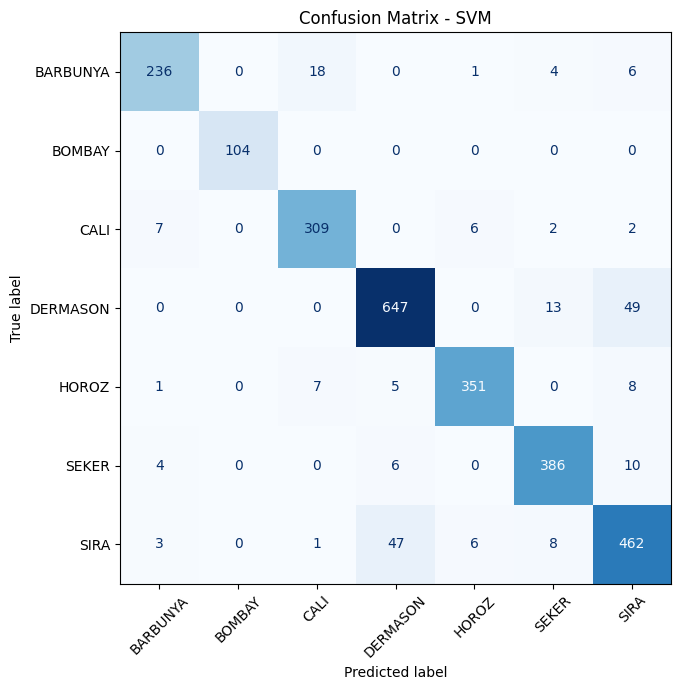

In [28]:
import matplotlib.pyplot as plt

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=model.classes_
    )

    fig, ax = plt.subplots(figsize=(9, 7))

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=model.classes_
    )

    display.plot(
        ax=ax,
        cmap="Blues",
        xticks_rotation=45,
        colorbar=False
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

## 14. Model Comparison and Observations

The performance of the five classification algorithms is compared using the six evaluation metrics.

The comparison helps identify the strengths and weaknesses of each algorithm and determine which classifier is most suitable for the Dry Bean Dataset.

The comparison table below presents the actual experimental results obtained from the testing dataset.

In [33]:
from IPython.display import display

display(results_df.round(4))

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9192,0.9934,0.9197,0.9192,0.9193,0.9023
1,Decision Tree,0.8966,0.9363,0.8965,0.8966,0.8964,0.8750
2,KNN,0.9155,0.9811,0.9163,0.9155,0.9157,0.8978
3,Gaussian Naive Bayes,0.8970,0.9899,0.8997,0.8970,0.8972,0.8762
4,SVM,0.9210,0.9933,0.9214,0.9210,0.9211,0.9045


### 14.1 Model Performance Observations

1. **Logistic Regression:** Achieved 91.92% accuracy and the highest AUC of 0.9934. It demonstrated excellent classification performance.

2. **Decision Tree:** Achieved 89.66% accuracy and an AUC of 0.9363. It recorded the lowest performance among the five models based on accuracy and AUC.

3. **K-Nearest Neighbors (KNN):** Achieved 91.55% accuracy and an MCC of 0.8978, showing good classification performance.

4. **Gaussian Naive Bayes:** Achieved 89.70% accuracy and an AUC of 0.9899. Its accuracy was lower than that of the leading models.

5. **Support Vector Machine (SVM):** Achieved the highest accuracy of 92.10%, Precision of 92.14%, Recall of 92.10%, F1-score of 92.11%, and MCC of 0.9045.

### 14.2 Overall Best Model

SVM is the best overall-performing model based on its highest Accuracy, Precision, Recall, F1-score, and MCC. Logistic Regression achieved a marginally higher AUC of 0.9934 compared with SVM's 0.9933.

Overall, all five classifiers demonstrated good performance on the Dry Bean classification dataset.

## 15. Saving the Trained Models

The five trained classification models are saved using Joblib. These saved model files will be used by the Streamlit application to make predictions and evaluate uploaded test data without retraining.

In [34]:
import os
import joblib

models_folder = "/content/drive/MyDrive/ML_Assignment_2/Models "

os.makedirs(models_folder, exist_ok=True)

model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Gaussian Naive Bayes": "gaussian_naive_bayes.joblib",
    "SVM": "svm.joblib"
}

for name, model in trained_models.items():
    file_path = os.path.join(models_folder, model_files[name])
    joblib.dump(model, file_path)
    print(name, "saved successfully")

Logistic Regression saved successfully
Decision Tree saved successfully
KNN saved successfully
Gaussian Naive Bayes saved successfully
SVM saved successfully


## 16. Saving the Test Dataset

The testing dataset is saved as a CSV file containing all 16 input features and the actual target column (Class). This dataset will be used to test the saved models through the Streamlit application.

In [36]:
test_data = X_test.copy()
test_data["Class"] = y_test

test_file_path = "/content/drive/MyDrive/ML_Assignment_2/Dataset /test_data.csv"

test_data.to_csv(test_file_path, index=False)

print("Test dataset saved successfully!")
print("Shape:", test_data.shape)
print("File location:", test_file_path)

Test dataset saved successfully!
Shape: (2709, 17)
File location: /content/drive/MyDrive/ML_Assignment_2/Dataset /test_data.csv
